# 🏏 IPL Deliveries Data Analysis | Python Case Study

## Problem Statement
This project analyses IPL ball-by-ball delivery data to understand scoring patterns, extras, batting performance, bowling performance, wickets, and innings-level trends.

## Objectives
- Explore the deliveries dataset and its columns.
- Understand runs, extras, and wickets.
- Identify high-scoring batters and wicket-taking bowlers.
- Compare teams' batting and bowling performance.
- Visualise patterns using charts.
- Summarise findings from the dataset.

**Dataset:** `deliveries.csv` — each row represents a delivery/ball record.

## 1. Dataset Description

The deliveries dataset contains ball-by-ball information, including match ID, innings, batting team, bowling team, over, ball, batter, bowler, runs, extras, and dismissal information.

> Note: A delivery row is not the same as a match. To calculate innings totals correctly, group by both `match_id` and `inning`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

### Load the dataset

If `deliveries.csv` is already in the Colab runtime, the notebook will load it directly. Otherwise, it will ask you to upload the CSV file.

In [ ]:
file_name = "deliveries.csv"

if not os.path.exists(file_name):
    try:
        from google.colab import files
        uploaded = files.upload()
        file_name = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Please place deliveries.csv in the same folder as this notebook."
        )

deliveries = pd.read_csv(file_name)
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2. Dataset Exploration

In [ ]:
print("Dataset Shape:", deliveries.shape)
print("\nColumn Names:")
print(deliveries.columns.tolist())

Dataset Shape: (164829, 21)

Column Names:
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batsman', 'non_striker', 'bowler', 'is_super_over', 'wide_runs', 'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs', 'batsman_runs', 'extra_runs', 'total_runs', 'player_dismissed', 'dismissal_kind', 'fielder']


In [ ]:
print("Dataset Information:")
deliveries.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164829 entries, 0 to 164828
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   match_id          164829 non-null  int64  
 1   inning            164829 non-null  int64  
 2   batting_team      164829 non-null  object 
 3   bowling_team      164829 non-null  object 
 4   over              164828 non-null  float64
 5   ball              164828 non-null  float64
 6   batsman           164828 non-null  object 
 7   non_striker       164828 non-null  object 
 8   bowler            164828 non-null  object 
 9   is_super_over     164828 non-null  float64
 10  wide_runs         164828 non-null  float64
 11  bye_runs          164828 non-null  float64
 12  legbye_runs       164828 non-null  float64
 13  noball_runs       164828 non-null  float64
 14  penalty_runs      164828 non-null  float64
 15  batsman_runs      164828 non-null  float64
 16 

In [ ]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1.0,1.0,DA Warner,S Dhawan,TS Mills,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
1,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1.0,2.0,DA Warner,S Dhawan,TS Mills,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
2,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1.0,3.0,DA Warner,S Dhawan,TS Mills,0.0,...,0.0,0.0,0.0,0.0,4.0,0.0,4.0,NaN,NaN,NaN
3,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1.0,4.0,DA Warner,S Dhawan,TS Mills,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
4,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,1.0,5.0,DA Warner,S Dhawan,TS Mills,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,NaN,NaN,NaN


In [ ]:
deliveries.sample(min(5, len(deliveries)), random_state=42)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
148654,629,2,Rising Pune Supergiants,Kings XI Punjab,3.0,4.0,AM Rahane,UT Khawaja,Sandeep Sharma,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
48399,205,2,Royal Challengers Bangalore,Kings XI Punjab,4.0,1.0,JH Kallis,MK Pandey,S Sreesanth,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
154081,7909,1,Kings XI Punjab,Sunrisers Hyderabad,17.0,6.0,KK Nair,CH Gayle,CJ Jordan,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
107741,455,1,Sunrisers Hyderabad,Rajasthan Royals,12.0,4.0,DJG Sammy,S Dhawan,STR Binny,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
75908,322,2,Kolkata Knight Riders,Rajasthan Royals,10.0,2.0,JH Kallis,MS Bisla,GB Hogg,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN


In [ ]:
print("Number of rows:", deliveries.shape[0])
print("Number of columns:", deliveries.shape[1])
print("Number of unique matches:", deliveries["match_id"].nunique())
print("Innings values:", sorted(deliveries["inning"].dropna().unique().tolist()))

Number of rows: 164829
Number of columns: 21
Number of unique matches: 697
Innings values: [1, 2, 3, 4]


## 3. Data Quality Check

The dataset is treated as already cleaned, as provided. These checks are included to document its current quality rather than make unnecessary changes.

In [ ]:
print("Missing values by column:")
display(deliveries.isnull().sum().to_frame("missing_values"))

Missing values by column:


,missing_values
match_id,0
inning,0
batting_team,0
bowling_team,0
over,1
ball,1
batsman,1
non_striker,1
bowler,1
is_super_over,1


In [ ]:
print("Duplicate rows:", deliveries.duplicated().sum())
print("\nData types:")
display(deliveries.dtypes.to_frame("data_type"))

Duplicate rows: 5

Data types:


,data_type
match_id,int64
inning,int64
batting_team,object
bowling_team,object
over,float64
ball,float64
batsman,object
non_striker,object
bowler,object
is_super_over,float64


## 4. Feature Classification

### Numerical features
Examples: `inning`, `over`, `ball`, `batsman_runs`, `extra_runs`, `total_runs`.

### Categorical/text features
Examples: `batting_team`, `bowling_team`, `batsman`, `bowler`, `dismissal_kind`.

The following cell classifies columns based on their current pandas data types.

In [ ]:
numeric_cols = deliveries.select_dtypes(include=np.number).columns.tolist()
categorical_cols = deliveries.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:")
print(numeric_cols)
print("\nCategorical/Text columns:")
print(categorical_cols)

Numerical columns:
['match_id', 'inning', 'over', 'ball', 'is_super_over', 'wide_runs', 'bye_runs', 'legbye_runs', 'noball_runs', 'penalty_runs', 'batsman_runs', 'extra_runs', 'total_runs']

Categorical/Text columns:
['batting_team', 'bowling_team', 'batsman', 'non_striker', 'bowler', 'player_dismissed', 'dismissal_kind', 'fielder']


# 5. Exploratory Data Analysis (EDA)

## 5.1 Univariate Analysis — Numerical Features

Univariate analysis studies one variable at a time.

In [ ]:
numeric_analysis_cols = [
    col for col in [
        "inning", "over", "ball", "batsman_runs", "extra_runs",
        "total_runs", "wide_runs", "noball_runs", "bye_runs",
        "legbye_runs", "is_super_over"
    ] if col in deliveries.columns
]

display(deliveries[numeric_analysis_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
inning,164829.0,1.482075,0.501583,1.0,1.0,1.0,2.0,4.0
over,164828.0,10.150326,5.675344,1.0,5.0,10.0,15.0,20.0
ball,164828.0,3.616194,1.807363,1.0,2.0,4.0,5.0,9.0
batsman_runs,164828.0,1.236993,1.603326,0.0,0.0,1.0,1.0,7.0
extra_runs,164828.0,0.067877,0.345088,0.0,0.0,0.0,0.0,7.0
total_runs,164828.0,1.304869,1.596086,0.0,0.0,1.0,1.0,10.0
wide_runs,164828.0,0.037166,0.254028,0.0,0.0,0.0,0.0,5.0
noball_runs,164828.0,0.004204,0.071136,0.0,0.0,0.0,0.0,5.0
bye_runs,164828.0,0.004896,0.114979,0.0,0.0,0.0,0.0,4.0
legbye_runs,164828.0,0.021550,0.196394,0.0,0.0,0.0,0.0,5.0


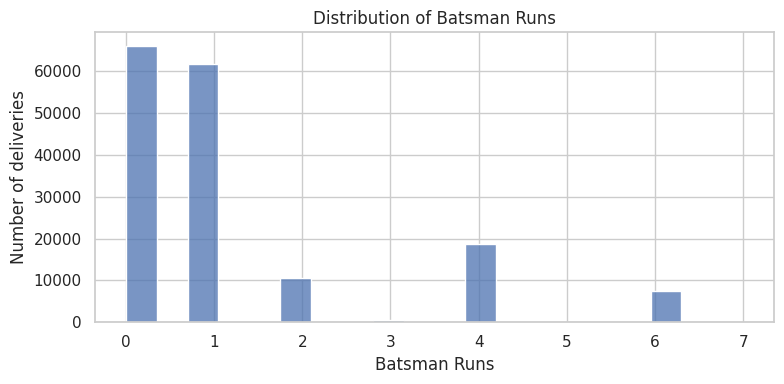

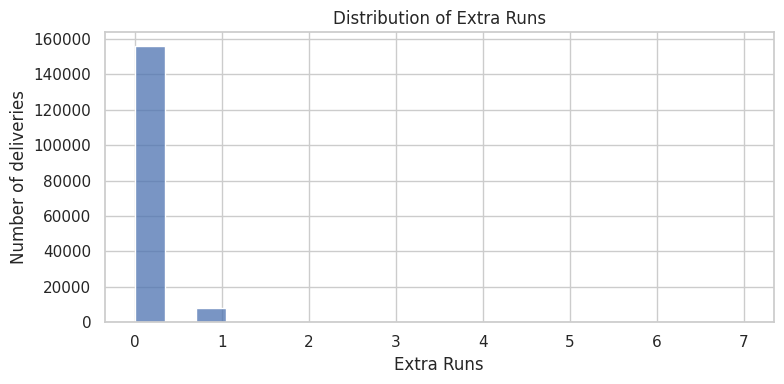

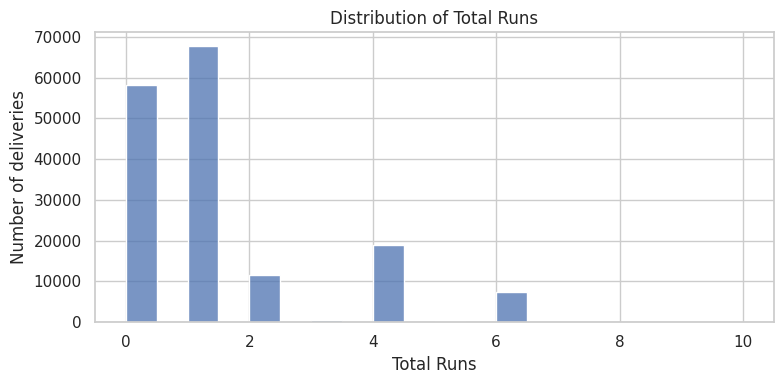

In [ ]:
for col in ["batsman_runs", "extra_runs", "total_runs"]:
    if col in deliveries.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(deliveries[col], bins=20)
        plt.title(f"Distribution of {col.replace('_', ' ').title()}")
        plt.xlabel(col.replace("_", " ").title())
        plt.ylabel("Number of deliveries")
        plt.tight_layout()
        plt.show()

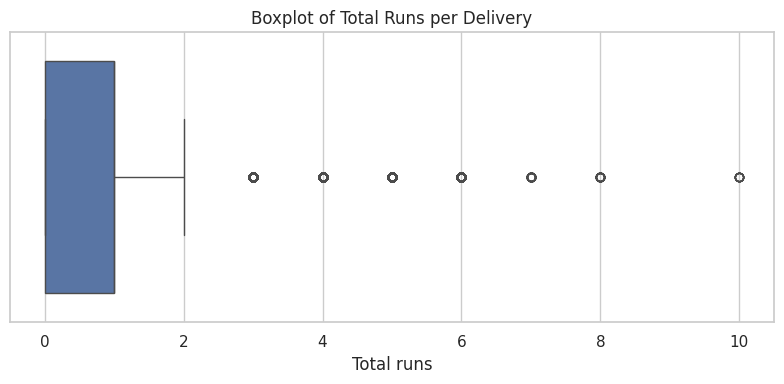

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=deliveries["total_runs"])
plt.title("Boxplot of Total Runs per Delivery")
plt.xlabel("Total runs")
plt.tight_layout()
plt.show()

### Univariate Analysis — Categorical Features

We examine the most frequent teams, batters, bowlers, and dismissal types.

In [ ]:
categorical_analysis_cols = [
    col for col in [
        "batting_team", "bowling_team", "batsman", "bowler", "dismissal_kind"
    ] if col in deliveries.columns
]

for col in categorical_analysis_cols:
    print(f"\nTop values for {col}:")
    display(deliveries[col].value_counts(dropna=False).head(10).to_frame("count"))


Top values for batting_team:


,count
batting_team,
Mumbai Indians,20673
Royal Challengers Bangalore,19379
Kings XI Punjab,19211
Kolkata Knight Riders,19155
Delhi Daredevils,18786
Chennai Super Kings,17711
Rajasthan Royals,15677
Sunrisers Hyderabad,11132
Deccan Chargers,9034



Top values for bowling_team:


,count
bowling_team,
Mumbai Indians,20573
Royal Challengers Bangalore,19627
Kolkata Knight Riders,19290
Kings XI Punjab,19055
Delhi Daredevils,18725
Chennai Super Kings,17611
Rajasthan Royals,15813
Sunrisers Hyderabad,10936
Deccan Chargers,9039



Top values for batsman:


,count
batsman,
V Kohli,3891
SK Raina,3723
G Gambhir,3524
RG Sharma,3497
S Dhawan,3384
RV Uthappa,3234
MS Dhoni,3001
AM Rahane,2925
DA Warner,2902



Top values for bowler:


,count
bowler,
Harbhajan Singh,3206
A Mishra,2929
PP Chawla,2890
SL Malinga,2694
R Ashwin,2673
P Kumar,2637
DJ Bravo,2448
UT Yadav,2366
B Kumar,2340



Top values for dismissal_kind:


,count
dismissal_kind,
NaN,156665
caught,4867
bowled,1495
run out,814
lbw,494
stumped,262
caught and bowled,211
retired hurt,11
hit wicket,9


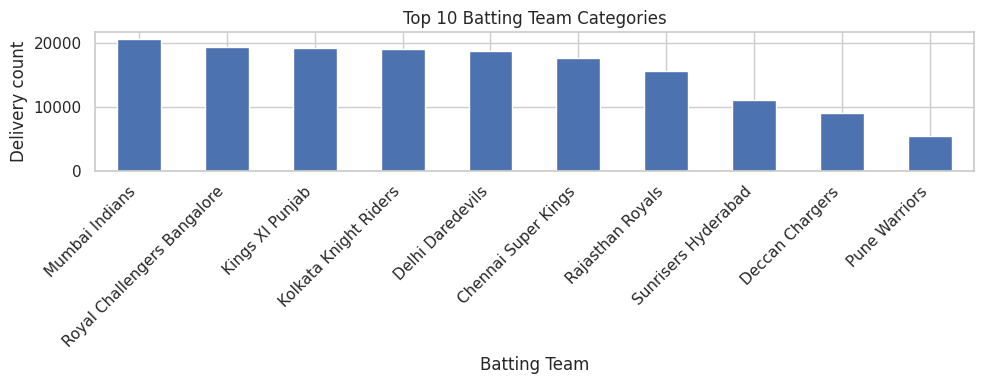

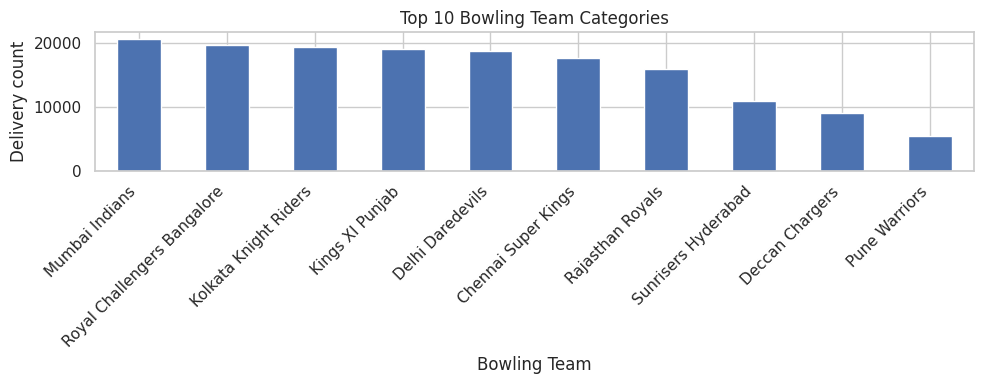

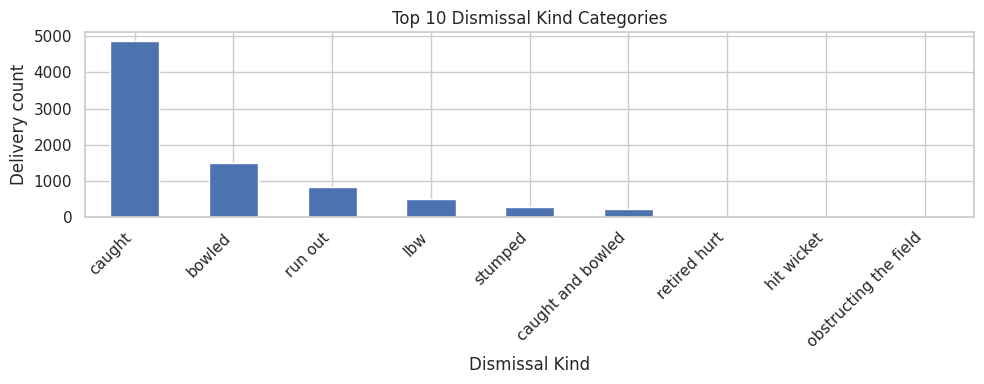

In [ ]:
for col in ["batting_team", "bowling_team", "dismissal_kind"]:
    if col in deliveries.columns:
        counts = deliveries[col].value_counts().head(10)
        plt.figure(figsize=(10, 4))
        counts.plot(kind="bar")
        plt.title(f"Top 10 {col.replace('_', ' ').title()} Categories")
        plt.xlabel(col.replace("_", " ").title())
        plt.ylabel("Delivery count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## 5.2 Innings-Level Analysis

Each match may contain multiple innings. We create a match-innings summary so that runs and extras are not incorrectly combined across every match.

In [ ]:
innings_summary = (
    deliveries.groupby(["match_id", "inning"], as_index=False)
    .agg(
        total_runs=("total_runs", "sum"),
        batsman_runs=("batsman_runs", "sum"),
        extra_runs=("extra_runs", "sum"),
        deliveries=("ball", "count")
    )
)

innings_summary.head()

,match_id,inning,total_runs,batsman_runs,extra_runs,deliveries
0,1,1,207.0,200.0,7.0,125
1,1,2,172.0,166.0,6.0,123
2,2,1,184.0,176.0,8.0,125
3,2,2,187.0,183.0,4.0,122
4,3,1,183.0,179.0,4.0,122


In [ ]:
print("Number of match-innings:", len(innings_summary))
display(innings_summary.groupby("inning")[["total_runs", "batsman_runs", "extra_runs"]].mean().round(2))

Number of match-innings: 1405


,total_runs,batsman_runs,extra_runs
inning,,,
1,161.26,152.89,8.37
2,147.70,140.00,7.70
3,13.71,13.00,0.71
4,11.00,10.29,0.71


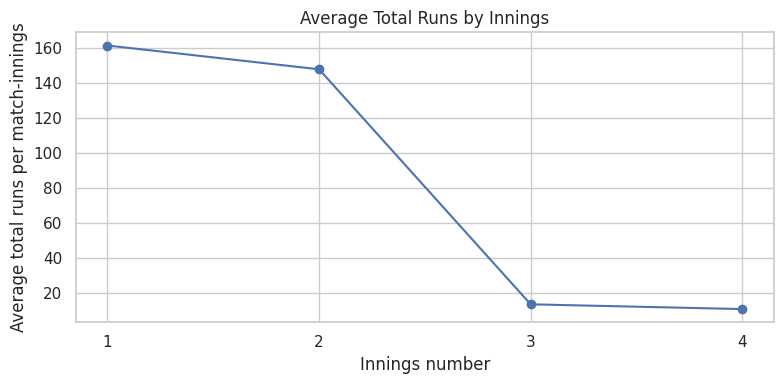

In [ ]:
# Average total runs by innings number
avg_runs_by_inning = innings_summary.groupby("inning")["total_runs"].mean().sort_index()

plt.figure(figsize=(8, 4))
plt.plot(avg_runs_by_inning.index, avg_runs_by_inning.values, marker="o")
plt.title("Average Total Runs by Innings")
plt.xlabel("Innings number")
plt.ylabel("Average total runs per match-innings")
plt.xticks(avg_runs_by_inning.index)
plt.tight_layout()
plt.show()

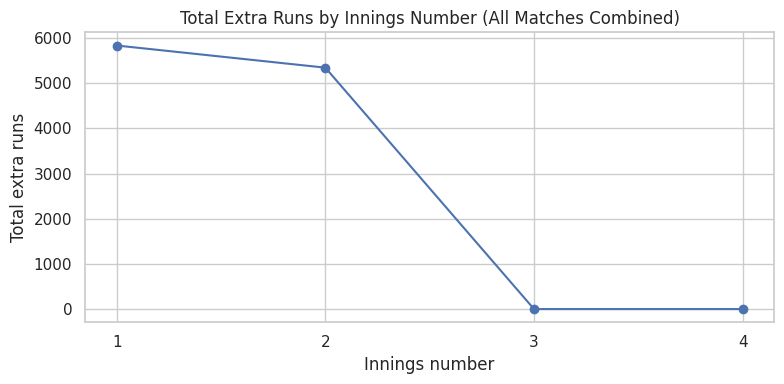

In [ ]:
# Total extras by innings number, summed across the dataset
extras_by_inning = deliveries.groupby("inning")["extra_runs"].sum().sort_index()

plt.figure(figsize=(8, 4))
plt.plot(extras_by_inning.index, extras_by_inning.values, marker="o")
plt.title("Total Extra Runs by Innings Number (All Matches Combined)")
plt.xlabel("Innings number")
plt.ylabel("Total extra runs")
plt.xticks(extras_by_inning.index)
plt.tight_layout()
plt.show()

## 5.3 Runs and Extras Analysis

In [ ]:
run_summary = deliveries[["batsman_runs", "extra_runs", "total_runs"]].sum().to_frame("total")
display(run_summary)

,total
batsman_runs,203891.0
extra_runs,11188.0
total_runs,215079.0


,runs
wide_runs,6126.0
legbye_runs,3552.0
bye_runs,807.0
noball_runs,693.0
penalty_runs,10.0


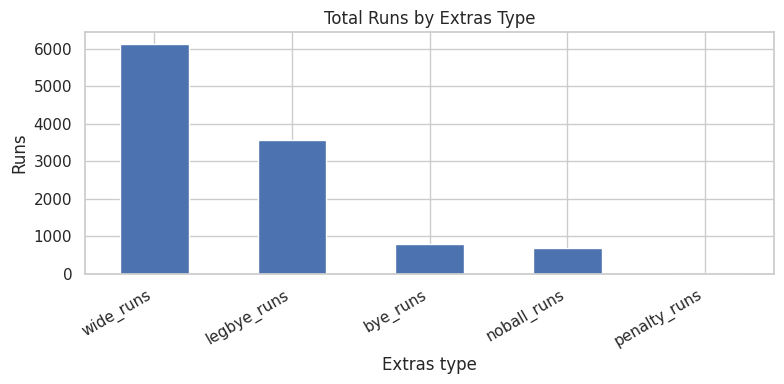

In [ ]:
extras_cols = [
    col for col in ["wide_runs", "noball_runs", "bye_runs", "legbye_runs", "penalty_runs"]
    if col in deliveries.columns
]
extras_summary = deliveries[extras_cols].sum().sort_values(ascending=False)
display(extras_summary.to_frame("runs"))

plt.figure(figsize=(8, 4))
extras_summary.plot(kind="bar")
plt.title("Total Runs by Extras Type")
plt.xlabel("Extras type")
plt.ylabel("Runs")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print("Total extra runs:", int(deliveries["extra_runs"].sum()))
print("Total runs:", int(deliveries["total_runs"].sum()))
print("Percentage of runs from extras:",
      round(deliveries["extra_runs"].sum() / deliveries["total_runs"].sum() * 100, 2)
      if deliveries["total_runs"].sum() else 0, "%")

Total extra runs: 11188
Total runs: 215079
Percentage of runs from extras: 5.2 %


## 5.4 Batting Performance

In [ ]:
batter_runs = (
    deliveries.groupby("batsman")["batsman_runs"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 run-scoring batters:")
display(batter_runs.head(10).to_frame("runs"))

Top 10 run-scoring batters:


,runs
batsman,
SK Raina,5014.0
V Kohli,4969.0
RG Sharma,4504.0
G Gambhir,4223.0
RV Uthappa,4144.0
S Dhawan,4090.0
MS Dhoni,4041.0
CH Gayle,4037.0
DA Warner,4014.0


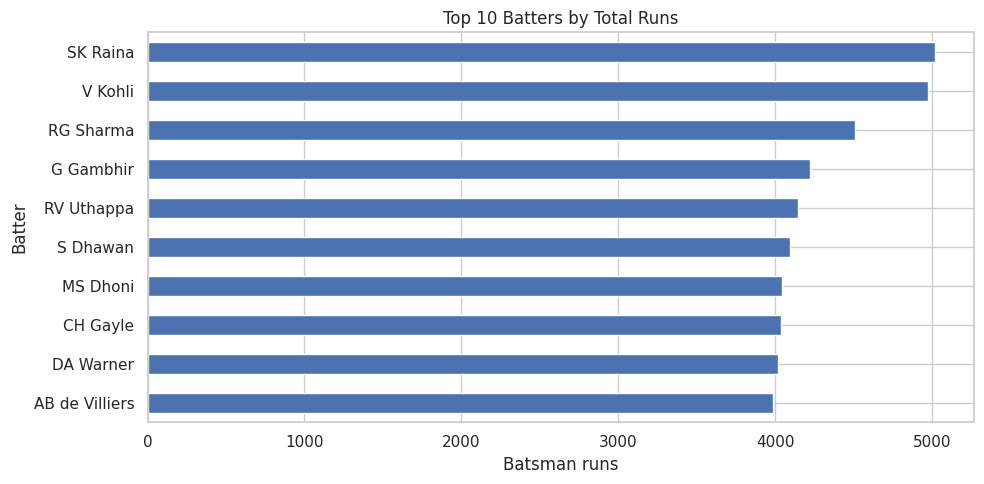

In [ ]:
plt.figure(figsize=(10, 5))
batter_runs.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Batters by Total Runs")
plt.xlabel("Batsman runs")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

In [ ]:
# Number of fours and sixes hit by each batter
fours = deliveries[deliveries["batsman_runs"] == 4].groupby("batsman").size()
sixes = deliveries[deliveries["batsman_runs"] == 6].groupby("batsman").size()

boundary_summary = pd.DataFrame({
    "fours": fours,
    "sixes": sixes
}).fillna(0).astype(int)

boundary_summary["total_boundaries"] = boundary_summary["fours"] + boundary_summary["sixes"]
display(boundary_summary.sort_values("total_boundaries", ascending=False).head(10))

,fours,sixes,total_boundaries
batsman,,,
SK Raina,448,186,634
CH Gayle,329,293,622
V Kohli,436,178,614
RG Sharma,379,185,564
DA Warner,401,160,561
RV Uthappa,408,146,554
G Gambhir,492,59,551
S Dhawan,461,85,546
AB de Villiers,326,188,514


## 5.5 Bowling Performance

In [ ]:
# Wickets credited to the bowler; run-outs, retired hurt, obstructing the field,
# and similar dismissals are excluded from bowler wicket counts.
non_bowler_dismissals = [
    "run out", "retired hurt", "obstructing the field", "retired out"
]

wicket_deliveries = deliveries[
    deliveries["player_dismissed"].notna()
    & ~deliveries["dismissal_kind"].str.lower().isin(non_bowler_dismissals)
]

bowler_wickets = wicket_deliveries.groupby("bowler").size().sort_values(ascending=False)

print("Top 10 bowlers by wickets credited:")
display(bowler_wickets.head(10).to_frame("wickets"))

Top 10 bowlers by wickets credited:


,wickets
bowler,
SL Malinga,154
A Mishra,146
PP Chawla,139
Harbhajan Singh,137
DJ Bravo,136
B Kumar,120
SP Narine,112
UT Yadav,111
R Ashwin,110


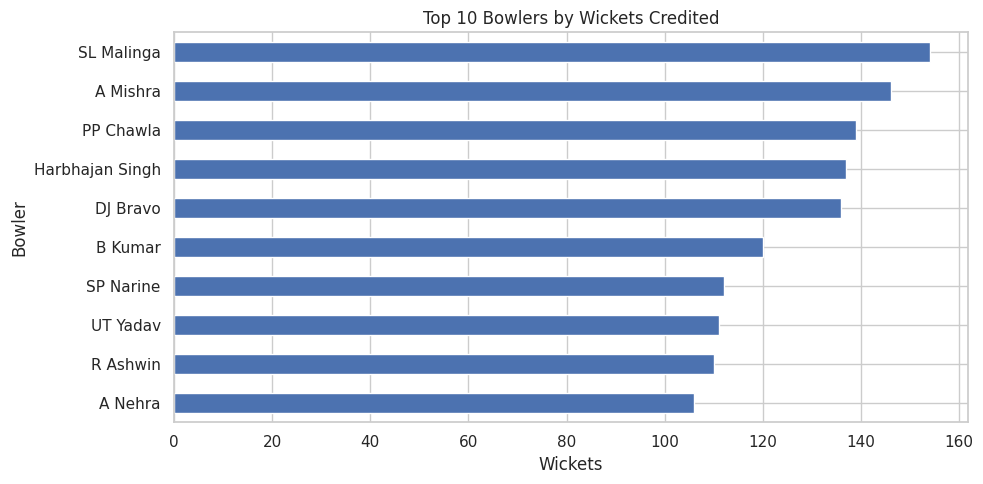

In [ ]:
plt.figure(figsize=(10, 5))
bowler_wickets.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Bowlers by Wickets Credited")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

In [ ]:
print("Dismissal types:")
display(deliveries["dismissal_kind"].value_counts(dropna=True).to_frame("count"))

Dismissal types:


,count
dismissal_kind,
caught,4867
bowled,1495
run out,814
lbw,494
stumped,262
caught and bowled,211
retired hurt,11
hit wicket,9
obstructing the field,1


## 6. Bivariate Analysis

Bivariate analysis studies the relationship between two variables.

### 6.1 Numerical vs Numerical

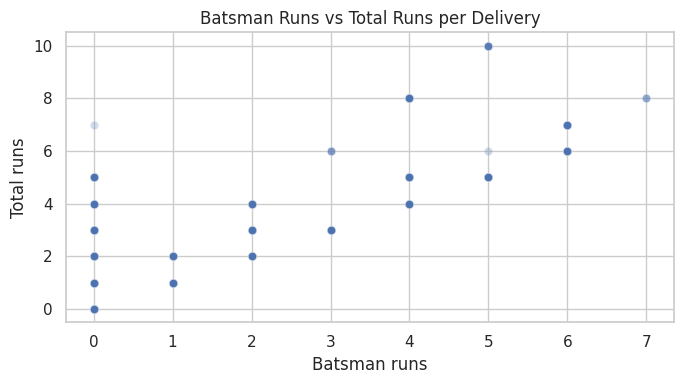

In [ ]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=deliveries, x="batsman_runs", y="total_runs", alpha=0.25)
plt.title("Batsman Runs vs Total Runs per Delivery")
plt.xlabel("Batsman runs")
plt.ylabel("Total runs")
plt.tight_layout()
plt.show()

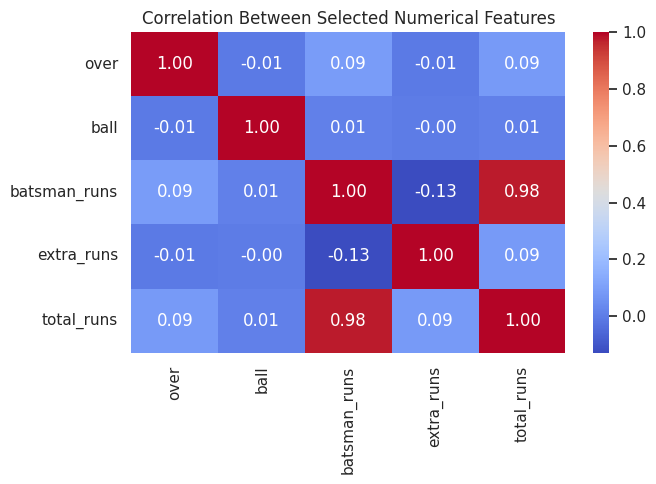

In [ ]:
correlation_cols = [
    col for col in ["over", "ball", "batsman_runs", "extra_runs", "total_runs"]
    if col in deliveries.columns
]
plt.figure(figsize=(7, 5))
sns.heatmap(deliveries[correlation_cols].corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Selected Numerical Features")
plt.tight_layout()
plt.show()

### 6.2 Numerical vs Categorical

In [ ]:
team_runs = (
    deliveries.groupby("batting_team")["total_runs"]
    .sum()
    .sort_values(ascending=False)
)
display(team_runs.to_frame("total_runs"))

,total_runs
batting_team,
Mumbai Indians,27026.0
Royal Challengers Bangalore,25898.0
Kings XI Punjab,25363.0
Kolkata Knight Riders,24828.0
Delhi Daredevils,24388.0
Chennai Super Kings,23819.0
Rajasthan Royals,20146.0
Sunrisers Hyderabad,14494.0
Deccan Chargers,11463.0


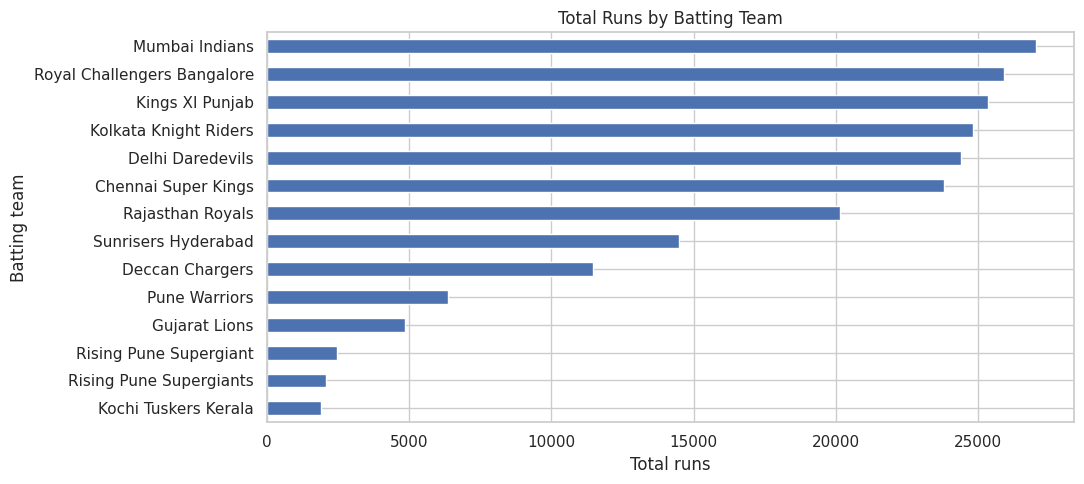

In [ ]:
plt.figure(figsize=(11, 5))
team_runs.sort_values().plot(kind="barh")
plt.title("Total Runs by Batting Team")
plt.xlabel("Total runs")
plt.ylabel("Batting team")
plt.tight_layout()
plt.show()

In [ ]:
team_avg_innings = (
    innings_summary.merge(
        deliveries[["match_id", "inning", "batting_team"]].drop_duplicates(),
        on=["match_id", "inning"],
        how="left"
    )
    .groupby("batting_team")["total_runs"]
    .mean()
    .sort_values(ascending=False)
)
display(team_avg_innings.to_frame("average_runs_per_innings"))

,average_runs_per_innings
batting_team,
Chennai Super Kings,160.939189
Mumbai Indians,157.127907
Gujarat Lions,156.838710
Kings XI Punjab,154.652439
Rising Pune Supergiant,154.375000
Sunrisers Hyderabad,154.191489
Royal Challengers Bangalore,153.242604
Deccan Chargers,152.840000
Delhi Daredevils,150.543210


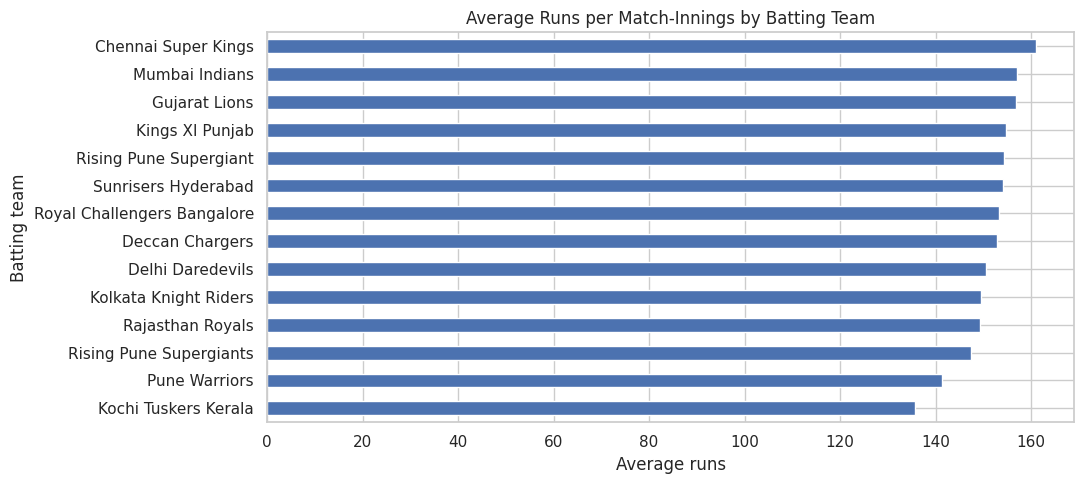

In [ ]:
plt.figure(figsize=(11, 5))
team_avg_innings.sort_values().plot(kind="barh")
plt.title("Average Runs per Match-Innings by Batting Team")
plt.xlabel("Average runs")
plt.ylabel("Batting team")
plt.tight_layout()
plt.show()

### 6.3 Team Matchups

In [ ]:
# Total runs scored by each batting team against each bowling team
team_matchup_runs = pd.pivot_table(
    deliveries,
    index="batting_team",
    columns="bowling_team",
    values="total_runs",
    aggfunc="sum",
    fill_value=0
)
display(team_matchup_runs)

bowling_team,Ch,Chennai Super Kings,Deccan Chargers,Delhi Daredevils,Gujarat Lions,Kings XI Punjab,Kochi Tuskers Kerala,Kolkata Knight Riders,Mumbai Indians,Pune Warriors,Rajasthan Royals,Rising Pune Supergiant,Rising Pune Supergiants,Royal Challengers Bangalore,Sunrisers Hyderabad
batting_team,,,,,,,,,,,,,,,
Chennai Super Kings,0.0,0.0,1592.0,2937.0,0.0,3254.0,283.0,2779.0,3837.0,905.0,3130.0,0.0,0.0,3310.0,1792.0
Deccan Chargers,0.0,1412.0,0.0,1790.0,0.0,1686.0,129.0,1297.0,1375.0,637.0,1427.0,0.0,0.0,1710.0,0.0
Delhi Daredevils,0.0,2636.0,1794.0,0.0,732.0,3079.0,297.0,3131.0,3224.0,864.0,2675.0,373.0,283.0,3427.0,1873.0
Gujarat Lions,0.0,0.0,0.0,724.0,0.0,647.0,0.0,660.0,655.0,0.0,0.0,333.0,360.0,771.0,712.0
Kings XI Punjab,0.0,3117.0,1632.0,3067.0,692.0,0.0,181.0,3629.0,3659.0,777.0,2743.0,237.0,325.0,3368.0,1936.0
Kochi Tuskers Kerala,0.0,276.0,74.0,260.0,0.0,178.0,0.0,288.0,184.0,148.0,207.0,0.0,0.0,286.0,0.0
Kolkata Knight Riders,0.0,2710.0,1378.0,3161.0,653.0,3685.0,265.0,0.0,3346.0,720.0,2619.0,339.0,228.0,3513.0,2211.0
Mumbai Indians,0.0,3872.0,1504.0,3621.0,656.0,3521.0,182.0,3614.0,0.0,804.0,2865.0,612.0,282.0,3817.0,1676.0
Pune Warriors,0.0,851.0,605.0,846.0,0.0,798.0,151.0,639.0,759.0,0.0,719.0,0.0,0.0,778.0,212.0


## 7. Multivariate Analysis

Multivariate analysis considers three or more variables together.

In [ ]:
# Average runs by batting team and innings
team_inning_runs = (
    innings_summary.merge(
        deliveries[["match_id", "inning", "batting_team"]].drop_duplicates(),
        on=["match_id", "inning"],
        how="left"
    )
    .groupby(["batting_team", "inning"])["total_runs"]
    .mean()
    .unstack()
)
display(team_inning_runs.round(2))

inning,1,2,3,4
batting_team,,,,
Chennai Super Kings,166.93,155.55,9.0,NaN
Deccan Chargers,157.33,146.81,NaN,NaN
Delhi Daredevils,157.08,146.82,NaN,11.00
Gujarat Lions,161.93,161.81,NaN,6.00
Kings XI Punjab,160.07,152.46,15.0,10.00
Kochi Tuskers Kerala,144.14,127.43,NaN,NaN
Kolkata Knight Riders,158.50,145.26,13.0,NaN
Mumbai Indians,165.88,149.00,11.0,NaN
Pune Warriors,148.65,135.40,NaN,NaN


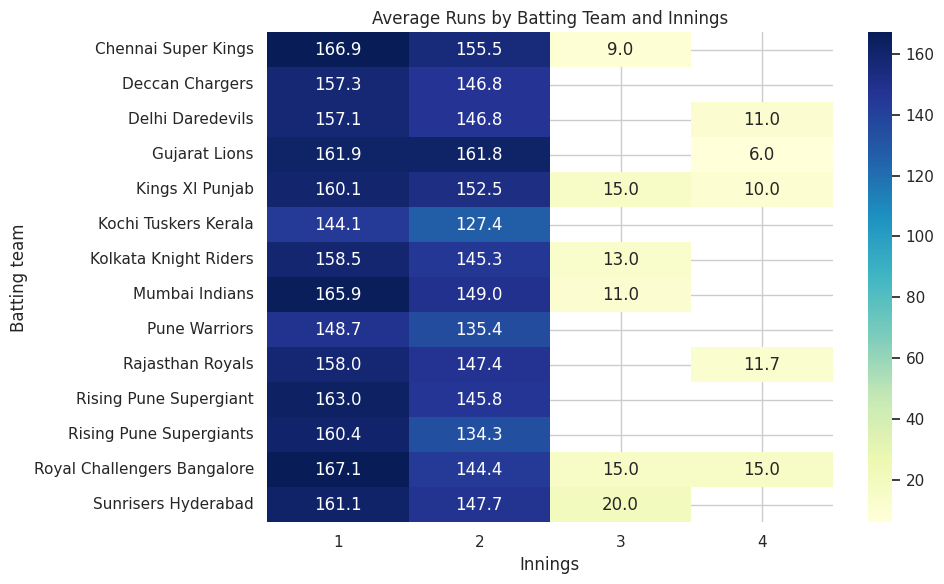

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(team_inning_runs, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Average Runs by Batting Team and Innings")
plt.xlabel("Innings")
plt.ylabel("Batting team")
plt.tight_layout()
plt.show()

In [ ]:
# Wickets by innings and dismissal type
dismissal_data = deliveries[deliveries["dismissal_kind"].notna()]
dismissal_table = pd.crosstab(dismissal_data["inning"], dismissal_data["dismissal_kind"])
display(dismissal_table)

dismissal_kind,bowled,caught,caught and bowled,hit wicket,lbw,obstructing the field,retired hurt,run out,stumped
inning,,,,,,,,,
1,760,2541,105,6,247,0,5,477,124
2,732,2320,106,3,246,1,6,333,138
3,1,4,0,0,1,0,0,3,0
4,2,2,0,0,0,0,0,1,0


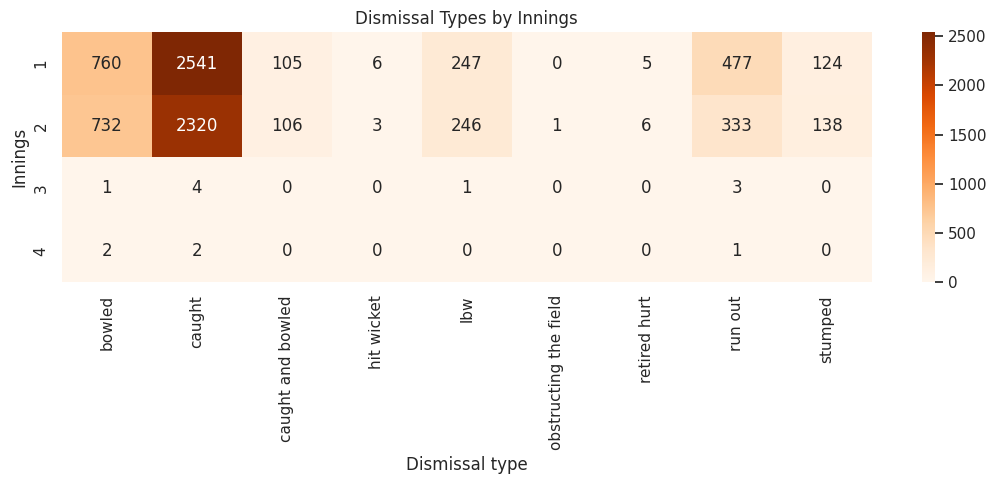

In [ ]:
plt.figure(figsize=(11, 5))
sns.heatmap(dismissal_table, annot=True, fmt="d", cmap="Oranges")
plt.title("Dismissal Types by Innings")
plt.xlabel("Dismissal type")
plt.ylabel("Innings")
plt.tight_layout()
plt.show()

## 8. Key Findings (Generated from the Dataset)

The following cells display the main results calculated from the uploaded data. Use these actual results when writing your final conclusions.

In [ ]:
print("PROJECT SUMMARY")
print("-" * 50)
print("Delivery records:", f"{len(deliveries):,}")
print("Unique matches:", f"{deliveries['match_id'].nunique():,}")
print("Total runs:", f"{int(deliveries['total_runs'].sum()):,}")
print("Total batsman runs:", f"{int(deliveries['batsman_runs'].sum()):,}")
print("Total extras:", f"{int(deliveries['extra_runs'].sum()):,}")

print("\nTop 5 run-scoring batters:")
display(batter_runs.head(5).to_frame("runs"))

print("\nTop 5 bowlers by wickets credited:")
display(bowler_wickets.head(5).to_frame("wickets"))

print("\nTop 5 batting teams by total runs:")
display(team_runs.head(5).to_frame("total_runs"))

print("\nMost common dismissal types:")
display(deliveries["dismissal_kind"].value_counts().head(5).to_frame("count"))

PROJECT SUMMARY
--------------------------------------------------
Delivery records: 164,829
Unique matches: 697
Total runs: 215,079
Total batsman runs: 203,891
Total extras: 11,188

Top 5 run-scoring batters:


,runs
batsman,
SK Raina,5014.0
V Kohli,4969.0
RG Sharma,4504.0
G Gambhir,4223.0
RV Uthappa,4144.0



Top 5 bowlers by wickets credited:


,wickets
bowler,
SL Malinga,154
A Mishra,146
PP Chawla,139
Harbhajan Singh,137
DJ Bravo,136



Top 5 batting teams by total runs:


,total_runs
batting_team,
Mumbai Indians,27026.0
Royal Challengers Bangalore,25898.0
Kings XI Punjab,25363.0
Kolkata Knight Riders,24828.0
Delhi Daredevils,24388.0



Most common dismissal types:


,count
dismissal_kind,
caught,4867
bowled,1495
run out,814
lbw,494
stumped,262


## 9. Conclusion

This project demonstrates how Python can be used to analyse IPL ball-by-ball data. The analysis covers scoring patterns, extras, batting and bowling performance, innings-level comparisons, dismissal types, and team matchups.

After running all cells, write a short conclusion based on the actual output. Avoid making claims that are not supported by the data.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## How to Run
1. Open this notebook in Google Colab.
2. Upload `deliveries.csv` when prompted (if it is not already in the runtime).
3. Select **Runtime → Run all**.
4. Review the tables, charts, and generated findings.